# 90 — Validação do código na carteira sintética

Este notebook compara o que o pipeline estima com a **verdade** que o gerador plantou. É teste de software
(o código recupera o que foi plantado quando as hipóteses valem?), **não evidência sobre o mercado**: na base
real não existe verdade, e a validação de negócio é o backtest fora do tempo (notebook 04).

Requer que o notebook 01 tenha rodado com `FONTE = "sintetico"` (ele grava a verdade em `data/synthetic/verdade`).

In [1]:
import sys, warnings
warnings.filterwarnings("ignore", message="Efeitos aleatórios com variância nula")   # informado explicitamente no notebook 03b
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from vgpricing.graficos import estilo
estilo()
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from vgpricing.config import carregar_config
from vgpricing.tabua import obter_tabua
from vgpricing.io import ler_pasta
from vgpricing.validacao import validar
from vgpricing.exposicao import exposicao_detalhada, experiencia
from vgpricing import manual as M, renovacao as R, backtest as B, verdade as V

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
cfg, cm, cr, cs, mapas = (carregar_config(n, RAIZ) for n in ("base", "manual", "renovacao", "sintetico", "colunas"))
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message=".*coluna lx.*")
    tabua = obter_tabua(cfg, RAIZ)
REF = pd.Timestamp(cfg["data_referencia"])
vpasta = RAIZ / "data/synthetic/verdade"
verd = {t: pd.read_parquet(vpasta / f"{t}.parquet") for t in ("verdade_estipulantes", "verdade_vidas", "verdade_ibnr", "verdade_sujeira")}
limpo = RAIZ / cfg["pasta_processados"] / "limpo"
dados = {t: pd.read_parquet(limpo / f"{t}.parquet") for t in ("estipulantes", "vidas", "sinistros", "premios")}

## 1. Qualidade de dados: a validação detecta exatamente o que foi sujo?

In [2]:
entrada, _ = ler_pasta(RAIZ / "data/synthetic/entrada", mapas, "parquet")
ex = validar(entrada, cfg).excecoes
linhas = []
for (tab, cod), g in verd["verdade_sujeira"].groupby(["tabela", "codigo"]):
    col = "id_linha" if tab == "vidas" else "id_sinistro"
    marc, inj = set(ex.loc[ex["codigo"] == cod, col].astype(str)), set(g["chave"].astype(str))
    linhas.append({"regra": cod, "injetados": len(inj), "detectados": len(marc & inj),
                   "não detectados": len(inj - marc), "falsos alarmes": len(marc - inj)})
pd.DataFrame(linhas)

,regra,injetados,detectados,não detectados,falsos alarmes
0,S01,82,82,0,0
1,S02,41,41,0,0
2,S04,41,41,0,0
3,V01,7393,7393,0,0
4,V03,1479,1479,0,0
5,V04,2957,2957,0,0
6,V05,7393,7393,0,0
7,V06,1479,1479,0,0
8,V07,1479,1479,0,0


## 2. O gerador não tem viés?

Óbitos simulados (avisados + IBNR + negados) contra $\sum E \times f$, com $f$ = seção × divisão × grupo.
A estatística $z = (O - E_f)/\sqrt{E_f}$ deve ficar perto de zero.

In [3]:
det = exposicao_detalhada(dados["vidas"], dados["estipulantes"], tabua, REF)
xp = experiencia(det, dados["sinistros"], dados["estipulantes"], REF)
g = xp.groupby("id_estipulante")[["obitos_esperados", "obitos_observados"]].sum().join(
    verd["verdade_estipulantes"].set_index("id_estipulante")["fator_verdadeiro"])
Ef = (g["obitos_esperados"] * g["fator_verdadeiro"]).sum()
negados = int((pd.read_parquet(RAIZ / "data/synthetic/entrada/sinistros.parquet")["status"] == "negado").sum())
O = g["obitos_observados"].sum() + len(verd["verdade_ibnr"]) + negados
pd.Series({"observados + IBNR + negados": O, "esperados × fator verdadeiro": Ef, "z": (O - Ef) / np.sqrt(Ef)}).to_frame("gerador")

,gerador
observados + IBNR + negados,"4,265.0000"
esperados × fator verdadeiro,"4,045.6322"
z,3.4489


Numa única carteira, $|z|$ até 2 ou 3 é compatível com o acaso (sob ausência de viés, $|z| > 2$ acontece em
cerca de 5% das carteiras). O teste automático `tests/test_sintetico.py::test_gerador_sem_vies` repete a
verificação em outra carteira.

## 3. Taxa manual: os fatores de seção recuperam a verdade?

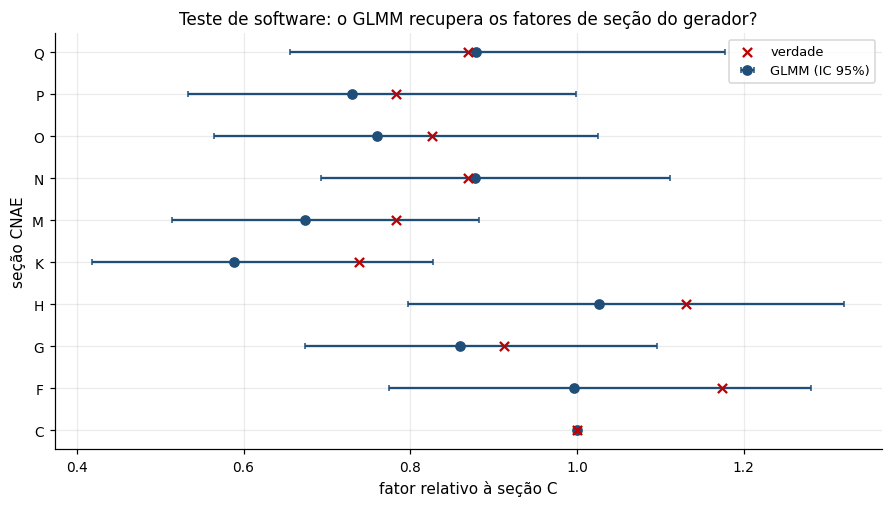

Variância entre grupos: estimada 0.1181 | verdadeira nesta carteira 0.0975


,estimado,ic95_inf,ic95_sup,verdade,IC cobre
seção,,,,,
C,1.0000,1.0000,1.0000,1.0000,True
F,0.9960,0.7746,1.2807,1.1739,True
G,0.8598,0.6743,1.0963,0.9130,True
H,1.0265,0.7978,1.3207,1.1304,True
K,0.5883,0.4185,0.8270,0.7391,True
M,0.6735,0.5139,0.8825,0.7826,True
N,0.8773,0.6928,1.1111,0.8696,True
O,0.7605,0.5643,1.0249,0.8261,True
P,0.7301,0.5335,0.9992,0.7826,True


In [4]:
cel, info = M.base_modelagem(dados["vidas"], dados["sinistros"], dados["estipulantes"], tabua, REF, cm)
final, _, _ = M.ajustar_taxa_manual(cel, cm)
base = final.especificacao["niveis_base"]["cnae_secao"]
coef = final.fixos.set_index("nome")
linhas = []
for s in sorted(cel["cnae_secao"].unique()):
    b, ep = (coef.loc[f"cnae_secao{s}", "estimativa"], coef.loc[f"cnae_secao{s}", "ep"]) if s != base else (0.0, 0.0)
    linhas.append({"seção": s, "estimado": np.exp(b), "ic95_inf": np.exp(b - 1.96 * ep), "ic95_sup": np.exp(b + 1.96 * ep)})
t = pd.DataFrame(linhas).set_index("seção")
t["verdade"] = V.relatividades_secao(verd["verdade_estipulantes"], base).reindex(t.index)
t["IC cobre"] = (t["ic95_inf"] <= t["verdade"]) & (t["verdade"] <= t["ic95_sup"])
fig, ax = plt.subplots(figsize=(8, 4.5)); y = np.arange(len(t))
ax.errorbar(t["estimado"], y, xerr=[t["estimado"] - t["ic95_inf"], t["ic95_sup"] - t["estimado"]], fmt="o", color="#1f4e79", capsize=2, label="GLMM (IC 95%)")
ax.scatter(t["verdade"], y, marker="x", color="#c00000", zorder=5, label="verdade")
ax.set_yticks(y, t.index); ax.set_ylabel("seção CNAE"); ax.set_xlabel(f"fator relativo à seção {base}")
ax.set_title("Teste de software: o GLMM recupera os fatores de seção do gerador?"); ax.legend(); plt.show()
print("Variância entre grupos: estimada", round(final.variancias["id_estipulante"], 4),
      "| verdadeira nesta carteira", round(float(np.var(np.log(verd["verdade_estipulantes"]["fator_grupo"]))), 4))
t

Duas razões para a cobertura numa única carteira não ser conclusiva: relatividades contra um nível base
herdam o erro da própria seção base; e, com poucos óbitos por grupo, a variância entre grupos pode sair
subestimada (comparação acima), o que estreita os intervalos. A sensibilidade das decisões a essa incerteza é avaliada na etapa de validação.

## 4. IBNR: o estimado bate com o verdadeiro?

In [5]:
tabela = M.carregar_tabela(RAIZ / "artefatos/fatores_manual.yaml")
ren = R.renovar_carteira(dados, tabua, tabela, cr, REF)
pd.Series({"IBNR estimado (óbitos)": ren["experiencia"]["IBNR_n"].sum(),
           "IBNR verdadeiro (avisados após a data de referência)": len(verd["verdade_ibnr"])}).to_frame("carteira")

,carteira
IBNR estimado (óbitos),134.2722
IBNR verdadeiro (avisados após a data de referência),144.0000


## 5. Renovação: qual credibilidade chega mais perto do custo esperado verdadeiro?

As previsões do backtest do notebook 04 comparadas com o custo **esperado** verdadeiro do ano-alvo (sem o sorteio
de Poisson), em valor limitado ao pooling. O nível de cada método é igualado à verdade antes do erro, para medir só
a estrutura (quem paga quanto em relação aos outros).

In [6]:
alvo = B.anos_alvo(dados["estipulantes"], REF, cr["backtest"]["meses_maturacao_alvo"])
cel0, info0 = M.base_modelagem(dados["vidas"], dados["sinistros"], dados["estipulantes"], tabua, alvo["inicio_ano"].min(), cm)
# mesmo método da taxa manual de produção (03b), só com dados anteriores
tabela0 = M.ajustar_tabela(cel0, tabela["meta"]["modelo_escolhido"], cm,
                           M.carregar_tabela(RAIZ / "artefatos/prioris_soa.yaml"), info0)
bt = B.executar(dados, tabua, tabela0, cr, REF)
det_alvo = det.merge(bt["alvo"][["id_estipulante", "ano_apolice"]], on=["id_estipulante", "ano_apolice"])
metodos = dict(B.METODOS) | {"premio_emitido": "Regra contratual (prêmio cobrado)"}
V.avaliar_contra_verdade(bt["por_grupo"], det_alvo, verd["verdade_estipulantes"], verd["verdade_vidas"],
                         bt["pooling_alvo"], cs["sinistros"]["prob_negado"], metodos)

,método,RMSE do log (estrutura)
1,"Credibilidade de mercado (raiz, vidas-ano)",0.2102
2,Bühlmann-Straub (n efetivo),0.2200
4,Regra contratual (prêmio cobrado),0.2864
0,Só taxa manual (Z = 0),0.3282
3,Só experiência (Z = 1),0.4400


Contra o custo esperado verdadeiro, as duas credibilidades ficam à frente da manual pura, da experiência pura e da
regra contratual, e próximas entre si: o que a teoria prevê. No backtest com dados realizados (notebook 04), um
único ano não tem poder para mostrar essa diferença.

## 6. Diagnóstico com ML: ele encontra estrutura quando ela existe?

Um resultado nulo do diagnóstico com LightGBM (notebook 03b) só tem valor se o método tiver poder para detectar estrutura real. Teste:
mantém a exposição e a taxa manual, sorteia os óbitos de novo com um efeito **plantado** numa região
(mortalidade multiplicada por $e$ nas idades indicadas), e verifica se o LightGBM melhora a deviance fora da
amostra com significância. Três sorteios por cenário.

In [7]:
from vgpricing import diagnostico as D
cmo = carregar_config("modelagem", RAIZ)
# células da taxa manual, com o esperado pela taxa manual de produção (03b)
dfd = cel.copy()
mult, _ = M.multiplicador_manual(dfd.assign(capital=cm["capital_referencia"] * np.exp(dfd["log_capital_c"])), tabela)
dfd["mu_manual"] = dfd["E"] * mult
VL = ["cnae_secao", "faixa_idade", "sexo", "log_capital_c", "faixa_tamanho"]
cd = D.config_lightgbm(cmo, "lightgbm_carteira", VL, [v for v in VL if v != "log_capital_c"])
mais50 = dfd["faixa_idade"].isin(["50-59", "60+"])
cenarios = {"construção (F), 50+": (dfd["cnae_secao"] == "F") & mais50,
            "indústria, construção e transporte (C/F/H), 50+": dfd["cnae_secao"].isin(["C", "F", "H"]) & mais50,
            "todas as seções, 50+": mais50}
linhas = []
for nome, regiao in cenarios.items():
    for efeito in (1.4, 1.8):
        detect = 0
        for semente in range(3):
            dp = dfd.assign(N=np.random.default_rng(100 + semente).poisson(dfd["mu_manual"] * np.where(regiao, efeito, 1.0)))
            detect += D.ajustar_residual(dp, cd)["comparacao"]["melhora_significativa"]
        linhas.append({"região": nome, "óbitos esperados na região": dfd.loc[regiao, "mu_manual"].sum(),
                       "efeito plantado": efeito, "detectado (de 3)": detect})
poder = pd.DataFrame(linhas)
poder

,região,óbitos esperados na região,efeito plantado,detectado (de 3)
0,"construção (F), 50+",132.3304,1.4000,1
1,"construção (F), 50+",132.3304,1.8000,1
2,"indústria, construção e transporte (C/F/H), 50+",653.6199,1.4000,3
3,"indústria, construção e transporte (C/F/H), 50+",653.6199,1.8000,3
4,"todas as seções, 50+","1,458.1096",1.4000,3
5,"todas as seções, 50+","1,458.1096",1.8000,3


Com o volume desta carteira, o diagnóstico com LightGBM só encontra estrutura que afeta **centenas** de óbitos
esperados: +80% numa região de ~310 esperados é detectado nos 3 sorteios, mas +40% só quando a região tem ~740. Um
efeito localizado, mesmo de +80% numa região de ~70 óbitos esperados, passa despercebido na maioria das vezes.

O mesmo efeito localizado (+40% em ~70 esperados), quando formulado como **hipótese dirigida** e testado no GLMM, é
detectado com folga:

In [8]:
regiao = cenarios["construção (F), 50+"]
dp = dfd.assign(N=np.random.default_rng(100).poisson(dfd["mu_manual"] * np.where(regiao, 1.4, 1.0)),
                F_50mais=np.where(regiao, "sim", "nao"))
D.testar_candidato_glmm(dp, cm, ["log_capital_c", "cnae_secao"], ["F_50mais"], categoricas_extras=["F_50mais"])

,termo,tipo,lr,gl,p_valor,coeficientes
0,F_50mais,fixo,12.4235,1,0.0004,{'F_50maissim': 1.4435}


**Leitura para a prática:** o ML exploratório é útil em bases grandes (os estudos de experiência da SOA que o
usam têm milhões de vidas). Em carteiras do porte desta, hipóteses de subscrição concretas devem ser testadas
diretamente no GLMM, que tem muito mais poder por ser dirigido. O notebook 03b aplica as duas coisas.